# Customer experience in European payments
## ECB SPACE 2024: a guided, reproducible case study
**Question:** Where do consumers encounter payment friction, and what could payment providers investigate next?

This notebook uses real public survey responses. It covers 40,981 consumers in 18 countries, excluding Germany and the Netherlands. Czechia is outside the survey. Start by reading the explanations, then run each cell. The source download verifies its bytes before use.

Source: European Central Bank. Findings are independent calculations, not official full-euro-area estimates.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'space_cx').exists():
    raise RuntimeError('Open this notebook from the project root or notebooks folder.')
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from space_cx.analysis import prepare, estimate, summarize, by_group, audit, standardized_age, GROUPS
from scripts.download_data import download

source = download()
raw = pd.read_csv(source)
df = prepare(raw)
print(f'{len(df):,} respondents, {df.COUNTRY.nunique()} countries, {len(raw.columns)} source columns')

40,981 respondents, 18 countries, 260 source columns


## 1. Understand the survey before calculating a metric
One row is one person, not one payment. The file includes repeated diary-payment columns, but this analysis uses respondent-level modules. In-store problems refer to the past month; online difficulties refer to payments reported for the diary day. Payment preferences are general attitudes.

The fieldwork spans autumn 2023 and spring 2024. These are cross-sectional rounds, not a panel. Telephone interviews and web panels have different selection mechanisms.

In [2]:
print('Coverage and sample sizes:')
display(df.groupby('country_name').size().rename('respondents').to_frame())
print('Interview modes and rounds:')
display(pd.crosstab(df.survey_mode, df.round_label))

Coverage and sample sizes:
Interview modes and rounds:


,respondents
country_name,
Austria,2531
Belgium,2562
Croatia,2546
Cyprus,1036
Estonia,1526
Finland,3062
France,5075
Greece,2070
Ireland,2043


round_label,Apr-Jun 2024,Sep-Nov 2023
survey_mode,,
Telephone,11428,9527
Web,10469,9557


## 2. Audit the coding and preserve unknown outcomes
In multi-select questions, 1 means selected and 0 means not selected. All zeros do not select the explicit 'no issues' option. Skipped questions are also different from negative answers. We exclude non-substantive sets from the primary question base.

A binary outcome therefore has three states: True, False and NA. The original source columns remain intact. Inspect the separate `valid_*` flags in `src/space_cx/analysis.py`.

In [3]:
audit_result = audit(raw, df, source)
print('Duplicate IDs:', audit_result['duplicate_ids'])
print('Missing / nonpositive weights:', audit_result['weight_missing_n'], audit_result['weight_nonpositive_n'])
display(pd.DataFrame(audit_result['question_response_audit']).T.fillna(''))
display(pd.Series(audit_result['valid_bases'], name='valid_n').to_frame())
display(df.pos_any.value_counts(dropna=False).rename('respondents').to_frame())

Duplicate IDs: 0
Missing / nonpositive weights: 0 0


,selected_any_n,all_zero_n,all_missing_n,exclusive_last_option_conflicts_n,always_with_barrier_conflicts_n,above_three_selections_n
acceptance,39123.0,1858.0,0.0,0.0,0.0,
pos,39404.0,1173.0,404.0,0.0,,
online,13884.0,127.0,26970.0,0.0,,
adoption,39940.0,1041.0,0.0,0.0,,0.0
privacy,38665.0,1821.0,495.0,0.0,,


,valid_n
valid_acceptance,38719
valid_pos,39404
valid_online,13884
valid_preference,40795
valid_auth,13722
valid_adoption,39940
valid_privacy,38579


,respondents
pos_any,
False,30508
True,8896
<NA>,1577


## 3. Build a valid-base weighted estimate
The weighted percentage is the weight of positive valid responses divided by the weight of all valid responses, multiplied by 100. Gross weights do not become response counts. Always show actual n separately.

Below, one person with several problems contributes once to the any-problem numerator.

In [4]:
valid = df.valid_pos
base = df.loc[valid]
positives = base.pos_any.astype(bool)
weighted_pct = 100 * base.loc[positives, 'Gross_weight'].sum() / base.Gross_weight.sum()
print(f'In-store technical problems: {weighted_pct:.4f}%, valid n={len(base):,}')
assert abs(weighted_pct - estimate(df, 'pos_any')['percent']) < 1e-10
keys = ['pos_any', 'accept_any', 'online_any', 'cashless_preference', 'privacy_any']
overview = summarize(df, keys)[['label','period','n','percent','effective_n_kish']]
display(overview.round(2))

In-store technical problems: 23.2402%, valid n=39,404


,label,period,n,percent,effective_n_kish
0,Any in-store technical problem,Past month,39404,23.24,12674.62
1,Preferred method unavailable or restricted,Past month,38719,23.57,12385.87
2,Any online payment difficulty,Diary day,13884,18.01,4266.58
3,Prefer cashless payments,General preference,40795,57.58,13097.30
4,Any privacy concern,General attitude,38579,64.44,12343.69


## 4. Inspect payment preference and friction
A stated preference is not an observed payment market share. Acceptance barriers are also different from technical failures. Report each construct using its own question.

**Interpretation:** about 58% prefer cashless payments. Around 23% report a technical in-store problem, and around 24% report an acceptance barrier. These are separate valid respondent groups.

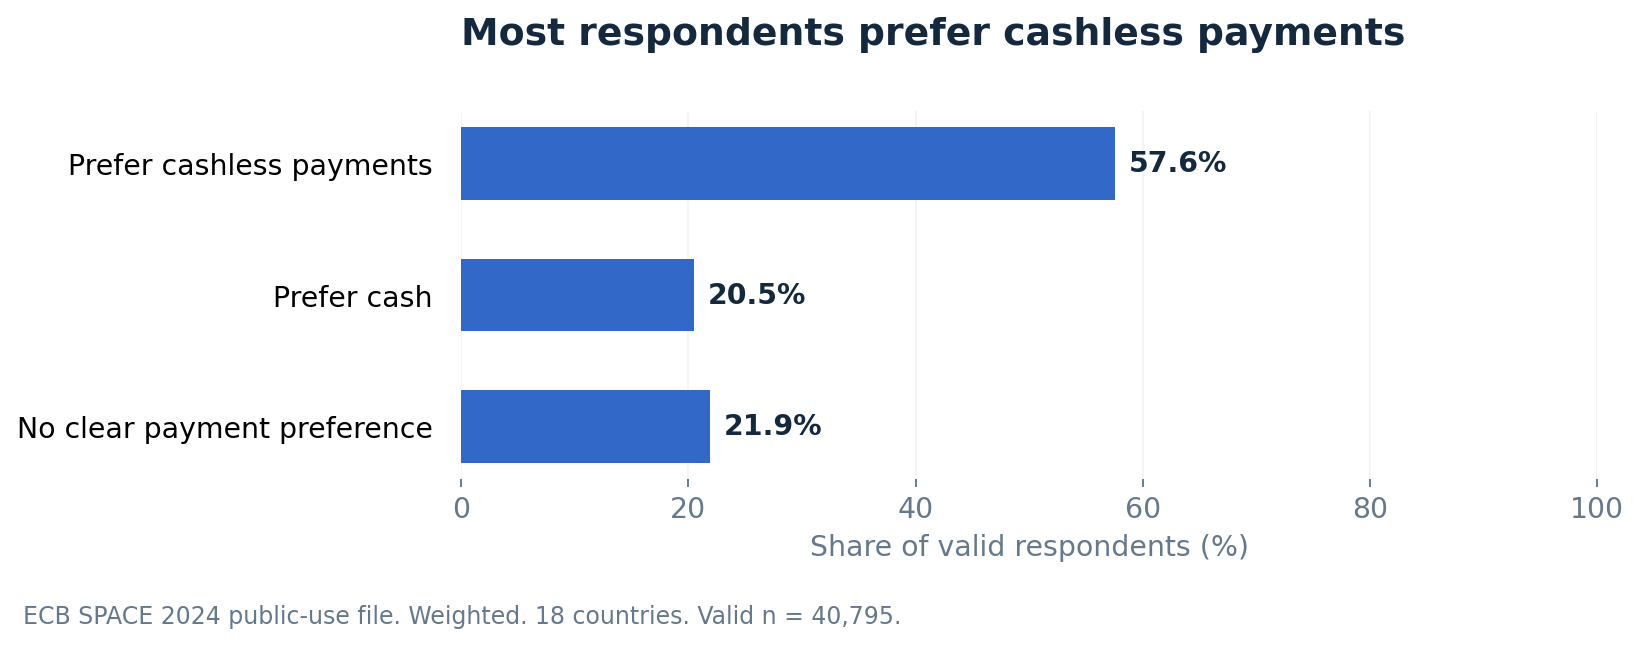

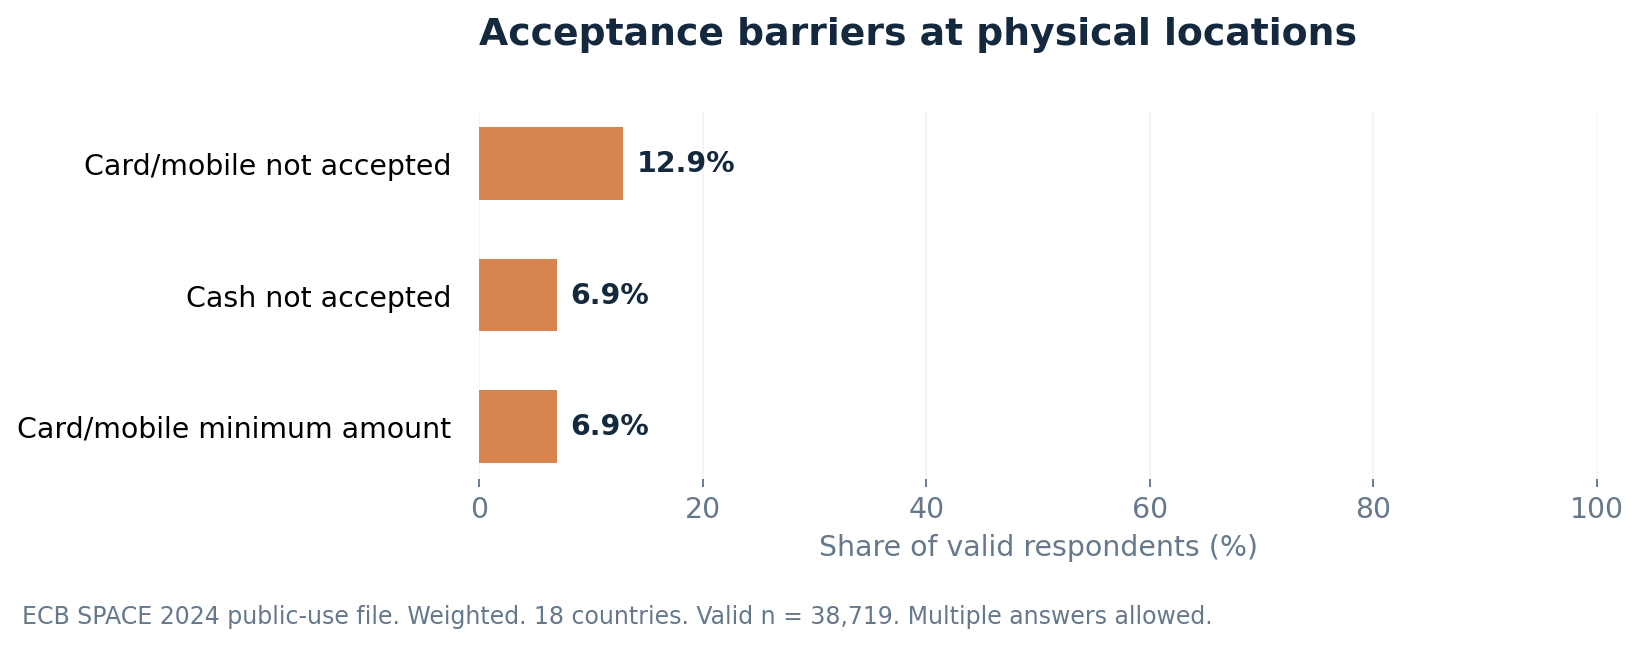

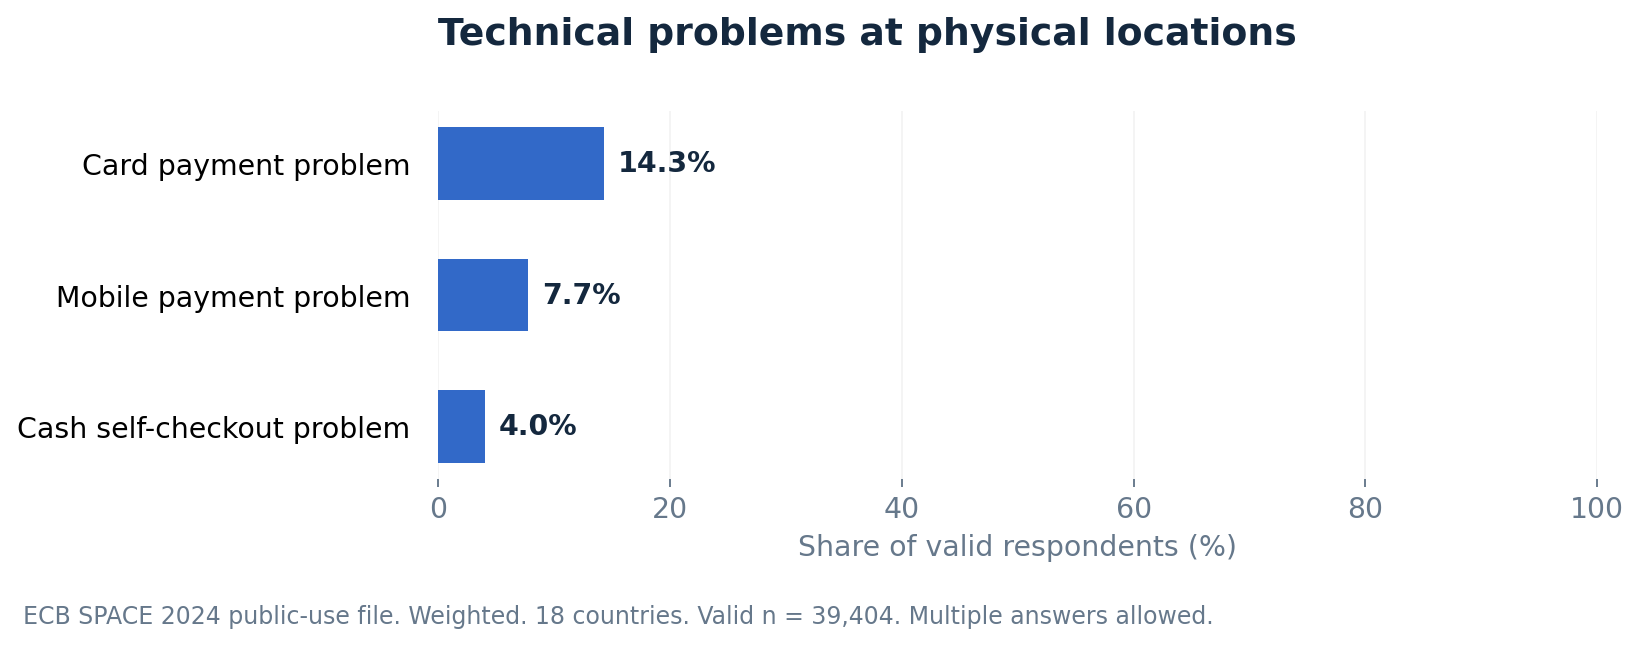

In [5]:
for name in ['01_preference', '02_acceptance', '03_pos_problems']:
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))

## 5. Investigate online checkout and stated adoption factors
Online data-entry difficulties, banking-app redirects and late passwords are distinct issues, with possible overlap. Their percentages are not a failed-transaction rate.

Security and ease both reach about 38% as reasons to try another payment solution. Their small numerical difference does not establish a clear lead. No causal adoption effect is measured.

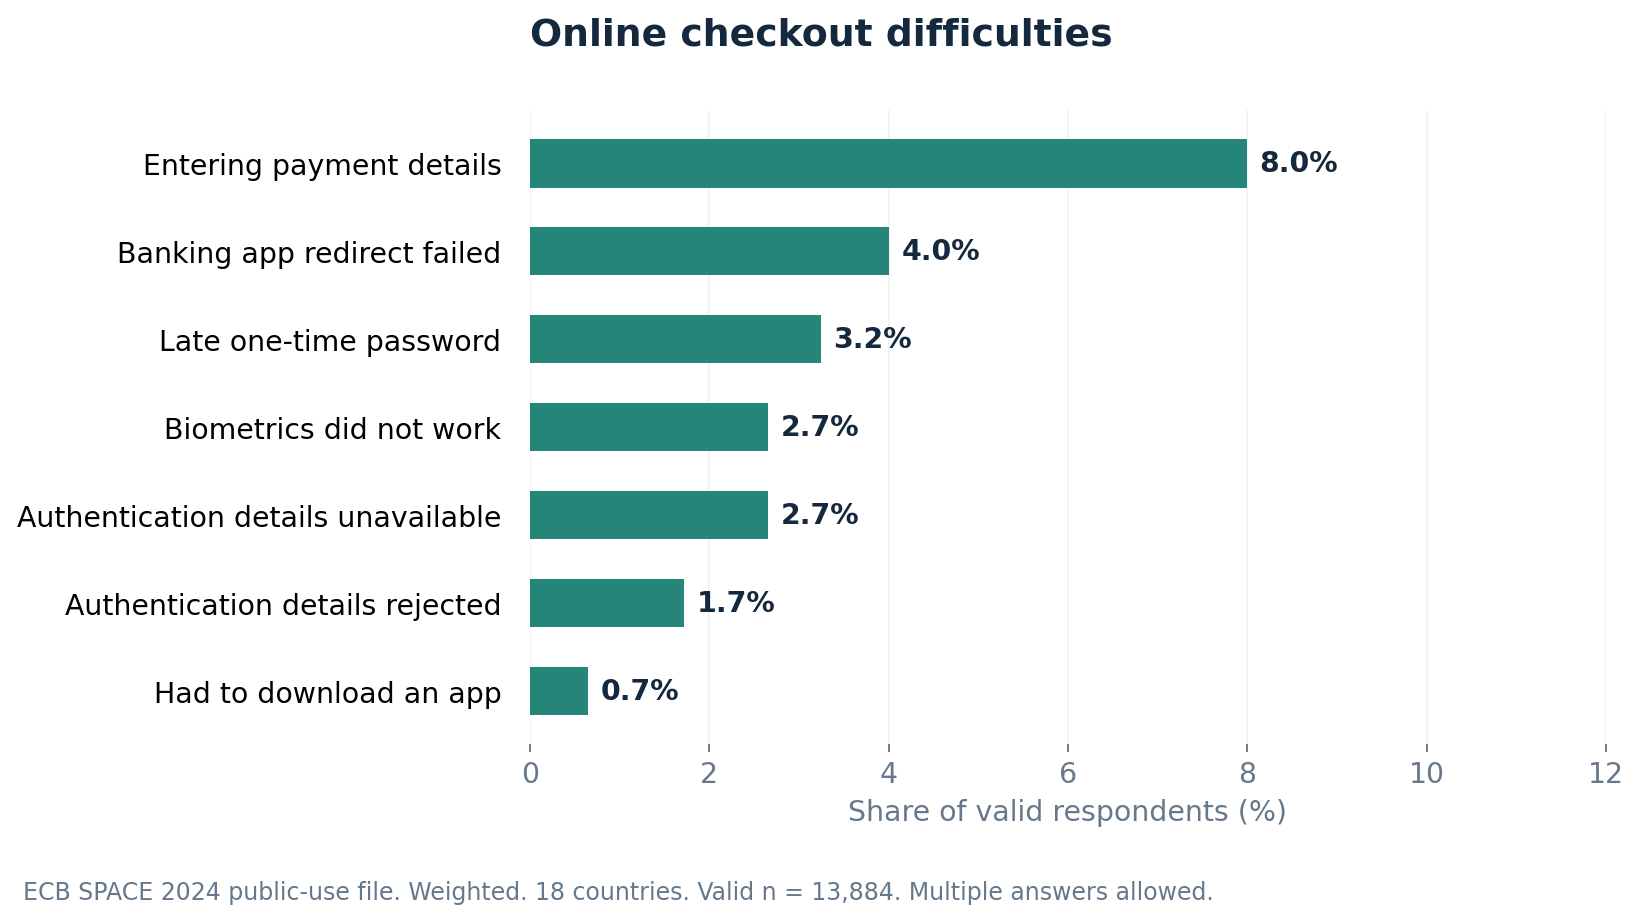

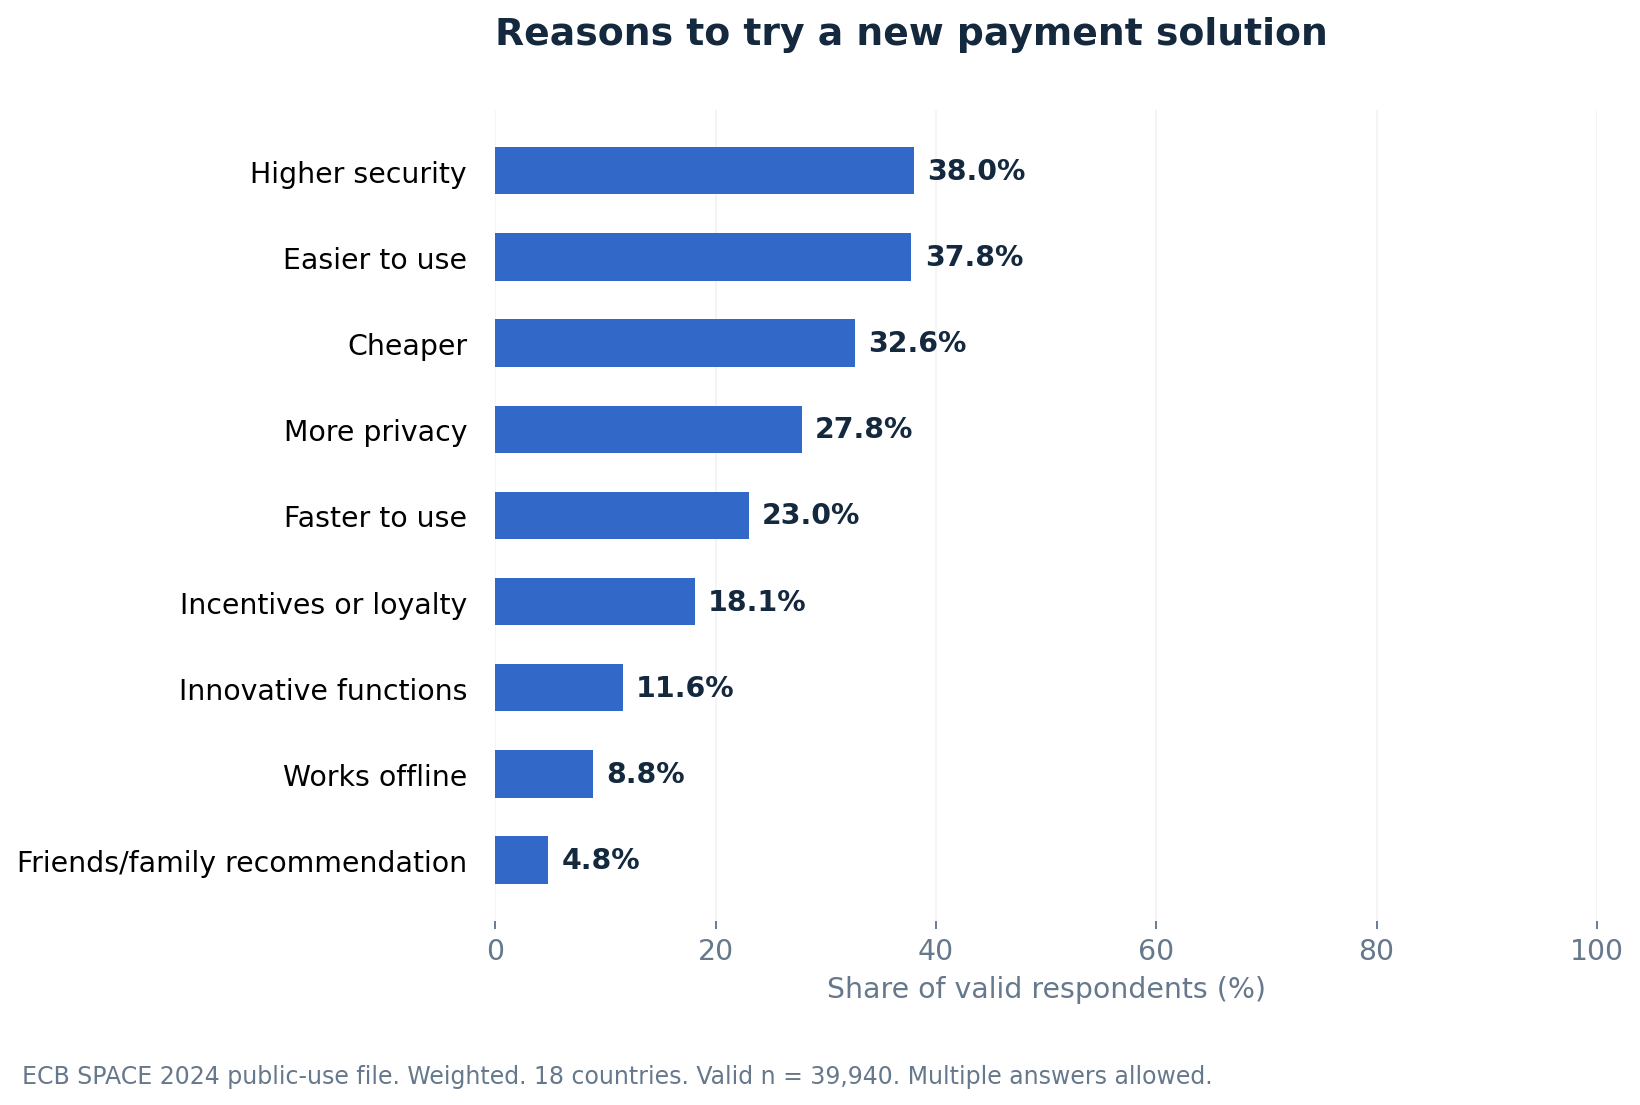

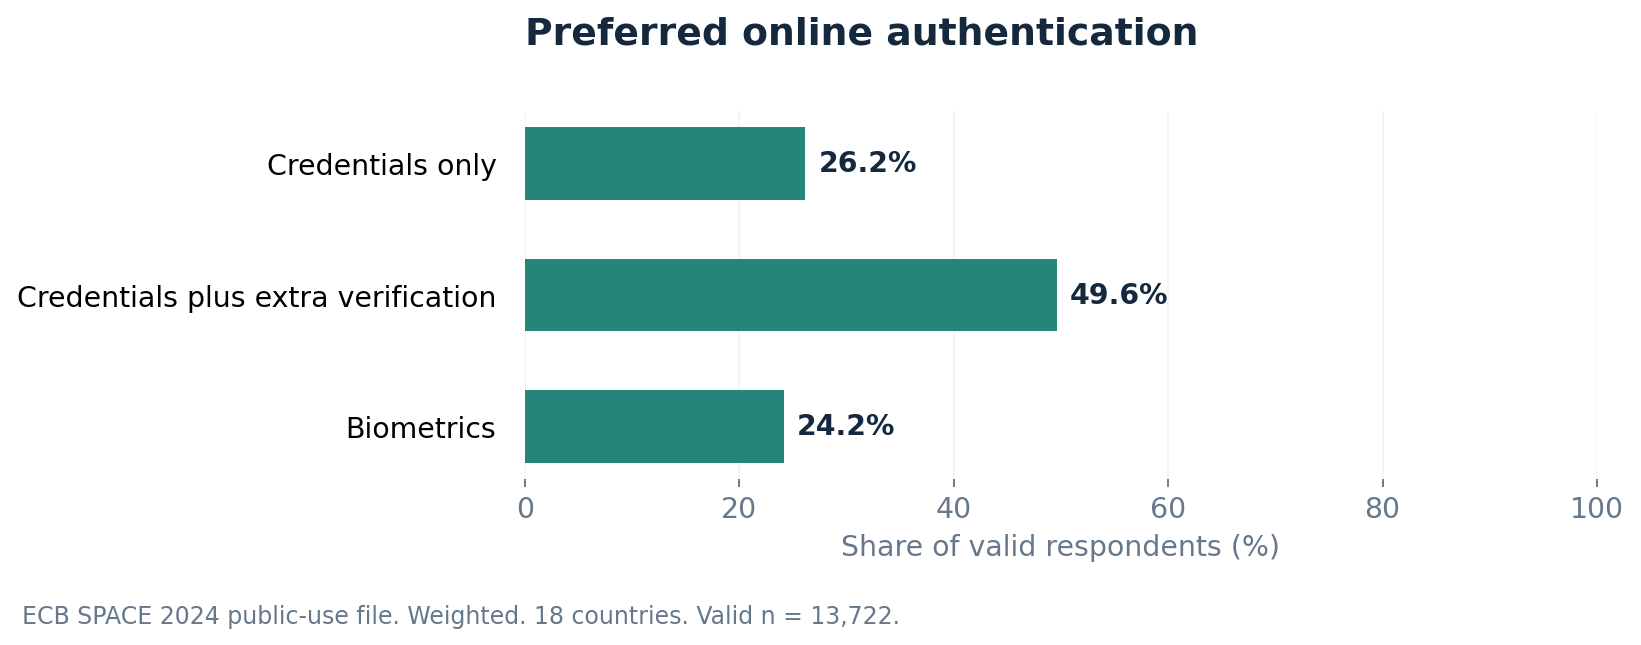

,label,n,percent
0,Any privacy concern,38579,64.44
1,Want more private transactions,38579,33.81
2,Concerned about use of data,38579,34.97


In [6]:
for name in ['04_online_problems', '05_adoption', '06_authentication']:
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))
display(summarize(df, ['privacy_any','privacy_1','privacy_2'])[['label','n','percent']].round(2))

## 6. Segment responsibly
Compare the age groups within the valid base of each metric. Younger respondents report more problems, but payment frequency, method use and reporting can differ. This does not measure capability.

A descriptive country-standardized comparison holds each age group's country mix fixed at the overall valid base. It addresses one compositional factor, not every confounder.

,group,label,n,percent
0,18-34,Any in-store technical problem,10103,28.63
1,18-34,Any online payment difficulty,3911,22.79
2,18-34,Prefer cashless payments,10444,59.40
3,35-54,Any in-store technical problem,13918,23.87
4,35-54,Any online payment difficulty,5264,17.97
5,35-54,Prefer cashless payments,14374,58.33
6,55+,Any in-store technical problem,15383,19.73
7,55+,Any online payment difficulty,4709,14.15
8,55+,Prefer cashless payments,15977,55.98


,metric,age_group,n,unadjusted_percent,country_standardized_percent
0,pos_any,18-34,10103,28.625,28.635
1,pos_any,35-54,13918,23.870,23.831
2,pos_any,55+,15383,19.728,19.719


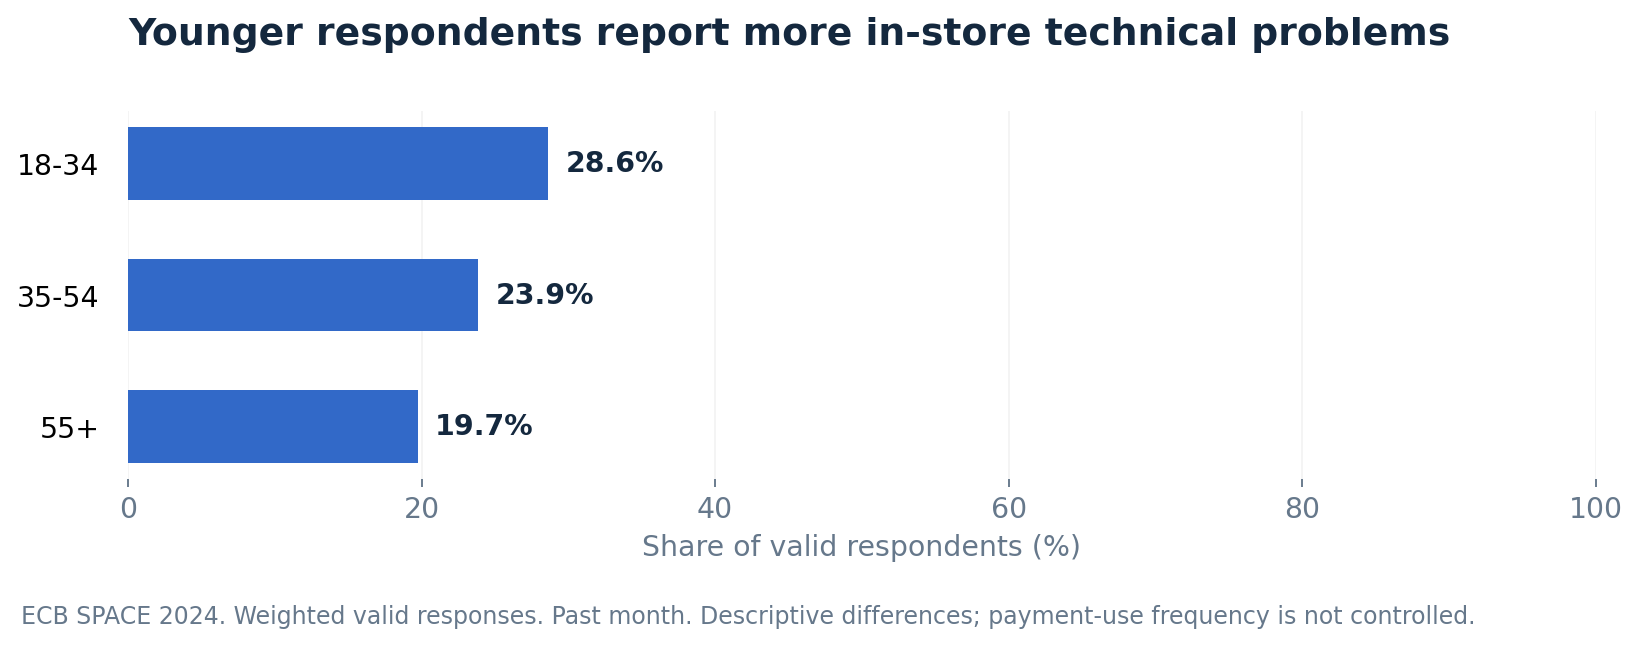

,group,n,percent
7,Greece,1985,26.71
8,Ireland,1973,25.18
13,Malta,1033,25.14
14,Portugal,2484,24.32
10,Latvia,991,24.31
15,Slovakia,2482,24.28
9,Italy,3908,23.72
3,Cyprus,1016,23.23
17,Spain,3886,22.97
6,France,4886,22.83


In [7]:
age = by_group(df, 'age_group', ['pos_any','online_any','cashless_preference'])
display(age[['group','label','n','percent']].round(2))
display(standardized_age(df, 'pos_any').round(3))
display(Image(filename=str(ROOT / 'outputs' / 'figures' / '07_age_pos.png')))
country = by_group(df, 'country_name', ['pos_any'])
display(country[['group','n','percent']].sort_values('percent', ascending=False).round(2))

## 7. Challenge the result before telling the story
Compare weighted and unweighted results. Examine survey-mode differences and the effect of retaining unknown records in a denominator. The alternative denominator below measures positive reports among eligible records, not a valid-answer problem rate.

Kish effective n diagnoses weight concentration. It cannot replace a full survey-design variance estimate. We avoid p-values and formal confidence intervals because the mixed probability/non-probability design and public file do not support a defensible full design-based analysis here.

In [8]:
from space_cx.analysis import denominator_sensitivity
comparison = summarize(df, keys)[['metric','percent']].merge(
    summarize(df, keys, weighted=False)[['metric','percent']], on='metric',
    suffixes=('_weighted','_unweighted'))
display(comparison.round(2))
display(denominator_sensitivity(df).drop(columns='interpretation').round(2))
display(by_group(df, 'survey_mode', ['pos_any','online_any'])[['group','label','n','percent']].round(2))

,metric,percent_weighted,percent_unweighted
0,pos_any,23.24,22.58
1,accept_any,23.57,23.09
2,online_any,18.01,16.75
3,cashless_preference,57.58,58.31
4,privacy_any,64.44,61.57


,metric,valid_n,eligible_n,valid_base_percent,positive_reports_per_eligible_records_percent
0,pos_any,39404,40577,23.24,22.40
1,accept_any,38719,40577,23.57,22.35
2,online_any,13884,14011,18.01,17.75


,group,label,n,percent
0,Telephone,Any in-store technical problem,19762,25.67
1,Telephone,Any online payment difficulty,4817,24.55
2,Web,Any in-store technical problem,19642,19.77
3,Web,Any online payment difficulty,9067,13.17


## 8. Turn evidence into testable actions
- Investigate incident types using terminal, network and authorisation logs alongside merchant support cases.
- Test payment-detail validation, error messages and recovery from authentication failures.
- Test simpler task flows with clear security explanations before adding product features.

Define operational success measures before running a pilot: completion rate, repeat attempts, incident recovery time, comprehension and support contacts. The survey supplies hypotheses, not ROI or causal uplift estimates.

**Next learning exercise:** choose Portugal or Slovakia, rerun the metric table, and explain every response base before comparing it with the pooled result.

In [9]:
selected_country = 'PT'  # change to SK, HR, SI, EE, LV, LT or another included country
country_df = df.loc[df.COUNTRY.eq(selected_country)]
display(summarize(country_df, keys)[['label','n','percent']].round(2))

,label,n,percent
0,Any in-store technical problem,2484,24.32
1,Preferred method unavailable or restricted,2446,20.51
2,Any online payment difficulty,789,13.59
3,Prefer cashless payments,2580,60.19
4,Any privacy concern,2452,71.65


## Reproducibility and sources
Run `python scripts/run_analysis.py` from the project root to rebuild the tables, figures, report, carousel and this executed notebook. Run `python -m unittest discover -s tests -v` for synthetic and source regression checks.

Read `reports/case_study.md`, `docs/survey_guide.md` and `docs/metric_dictionary.csv` for the business interpretation and exact coding. The carousel is `presentation/space_2024_linkedin_carousel.pdf`.

[ECB source](https://www.ecb.europa.eu/stats/ecb_surveys/space/html/index.en.html) | [Questionnaire](https://www.ecb.europa.eu/stats/ecb_surveys/space/shared/pdf/ecb.space2024_annex_a.en.pdf) | [Methodology](https://www.ecb.europa.eu/stats/ecb_surveys/space/shared/pdf/ecb.space2024_annex_b.en.pdf)

Source data: European Central Bank. All estimates are independent calculations for the 18-country public-use file. No ECB endorsement.